In [16]:
pip install shap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import pandas as pd
import numpy as np

import shap
import joblib

import matplotlib.pyplot as plt

In [19]:
model = joblib.load("../models/best_model.pkl")
print(type(model))

print("LightGBM Model Loaded Successfully")

<class 'lightgbm.sklearn.LGBMClassifier'>
LightGBM Model Loaded Successfully


In [20]:
# ==========================================
# Load Dataset
# ==========================================

X_train = pd.read_csv("../data/X_train.csv")

X_test = pd.read_csv("../data/X_test.csv")

print(X_train.shape)

print(X_test.shape)

(24000, 113)
(6000, 113)


In [21]:
# ==========================================
# Create SHAP Explainer
# ==========================================

explainer = shap.Explainer(model)

print("Explainer Created Successfully")

Explainer Created Successfully


In [22]:
# ==========================================
# Calculate SHAP Values
# ==========================================

shap_values = explainer(X_test)

print(type(shap_values))
print(shap_values.shape)

<class 'shap._explanation.Explanation'>
(6000, 113, 3)


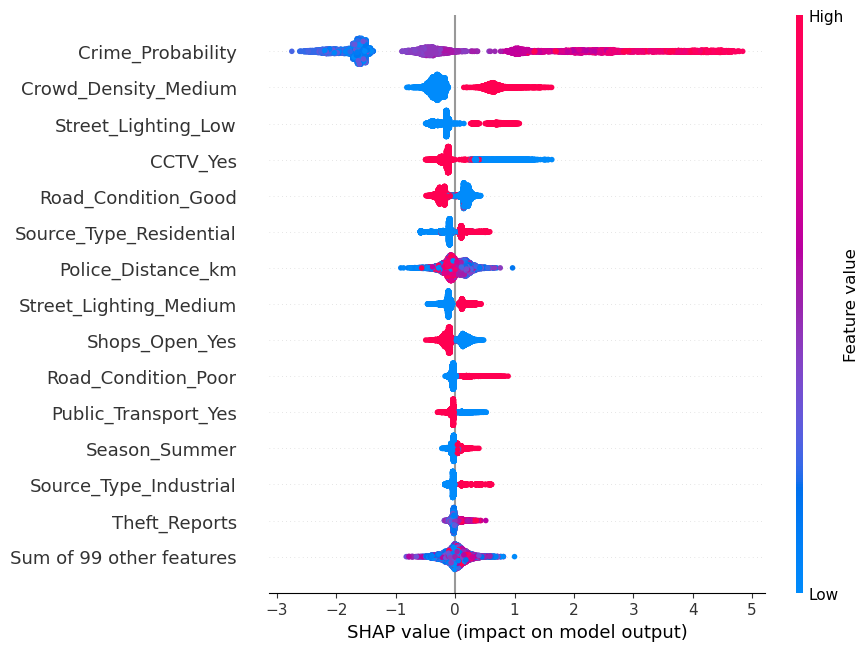

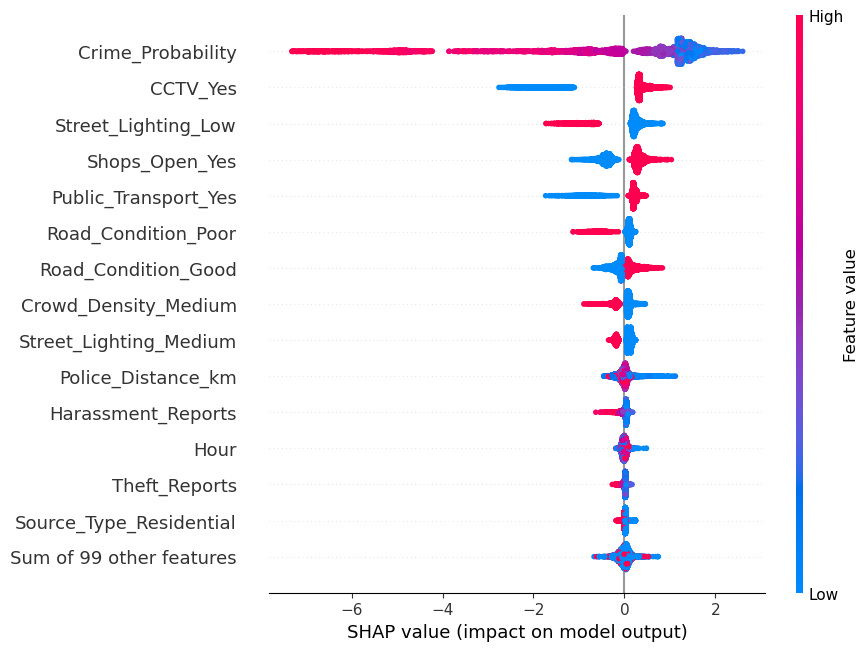

In [24]:
shap.plots.beeswarm(
    shap_values[:, :, 0],
    max_display=15
)
shap.plots.beeswarm(
    shap_values[:, :, 1],
    max_display=15
)

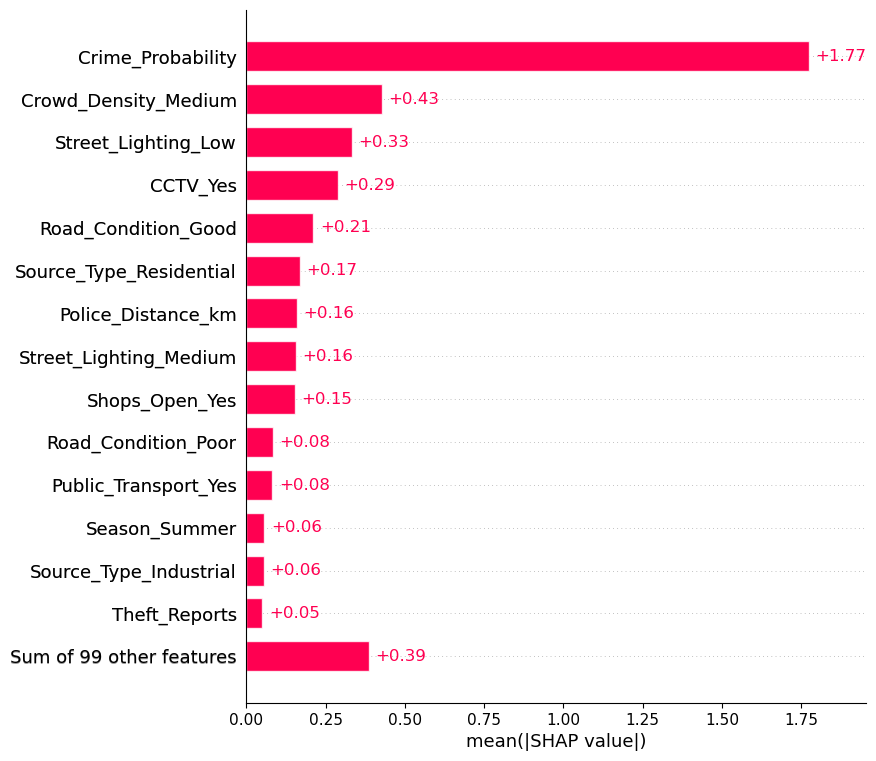

In [25]:
shap.plots.bar(
    shap_values[:, :, 0],
    max_display=15
)

In [27]:
sample_index = 0

prediction = model.predict(
    X_test.iloc[[sample_index]]
)[0]

print("Predicted Class:", prediction)

Predicted Class: 1


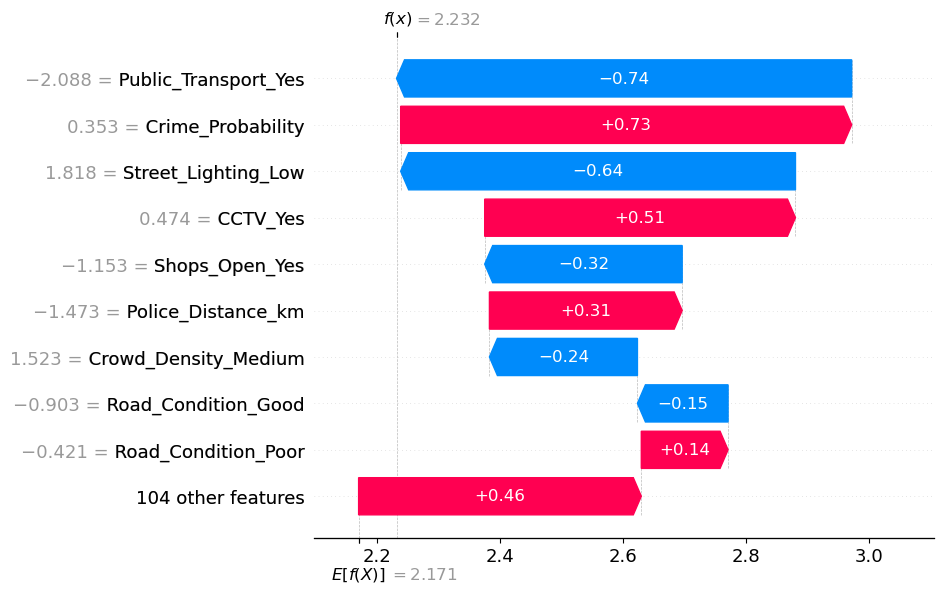

In [28]:
sample_index = 0

class_index = int(prediction)

shap.plots.waterfall(
    shap_values[sample_index, :, class_index]
)

In [30]:
shap.initjs()

shap.plots.force(
    shap_values[sample_index, :, class_index]
)

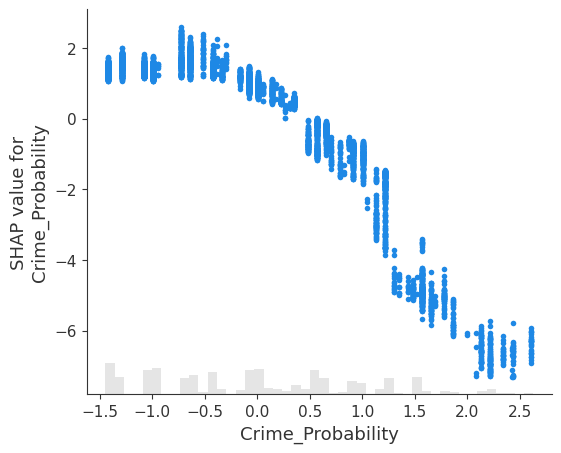

In [31]:
shap.plots.scatter(
    shap_values[:, "Crime_Probability", class_index]
)

In [32]:
label_names = {
    0: "Moderate",
    1: "Safe",
    2: "Unsafe"
}

sample_index = 0

prediction = model.predict(X_test.iloc[[sample_index]])[0]

prediction_label = label_names[int(prediction)]

print("Prediction:", prediction_label)

Prediction: Safe


In [33]:
class_index = int(prediction)

sample_shap = shap_values[sample_index, :, class_index]

In [34]:
feature_df = pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP Value": sample_shap.values
})

feature_df["Absolute"] = feature_df["SHAP Value"].abs()

feature_df = feature_df.sort_values(
    by="Absolute",
    ascending=False
)

feature_df.head(10)

,Feature,SHAP Value,Absolute
110,Public_Transport_Yes,-0.740018,0.740018
8,Crime_Probability,0.733256,0.733256
95,Street_Lighting_Low,-0.641875,0.641875
107,CCTV_Yes,0.505278,0.505278
109,Shops_Open_Yes,-0.321084,0.321084
11,Police_Distance_km,0.313393,0.313393
100,Crowd_Density_Medium,-0.240648,0.240648
111,Road_Condition_Good,-0.147350,0.147350
112,Road_Condition_Poor,0.141063,0.141063
84,Dest_Type_Educational,0.102717,0.102717


In [35]:
feature_messages = {

    "Crime_Probability":
        "High crime probability",

    "Police_Distance_km":
        "Police station is far away",

    "Weather_Rain":
        "Rainy weather",

    "Weather_Fog":
        "Fog reduces visibility",

    "Street_Lighting_Low":
        "Poor street lighting",

    "Street_Lighting_Medium":
        "Moderate street lighting",

    "CCTV_No":
        "No CCTV surveillance",

    "Visibility_Low":
        "Low visibility",

    "Crowd_Density_Low":
        "Low crowd density",

    "Road_Condition_Poor":
        "Poor road condition"
}

In [36]:
print("="*50)
print("SAFEPATH AI EXPLANATION")
print("="*50)

print("\nPrediction:", prediction_label)

print("\nTop Reasons:")

count = 0

for _, row in feature_df.iterrows():

    feature = row["Feature"]

    if feature in feature_messages:

        print("✔", feature_messages[feature])

        count += 1

    if count == 5:
        break

SAFEPATH AI EXPLANATION

Prediction: Safe

Top Reasons:
✔ High crime probability
✔ Poor street lighting
✔ Police station is far away
✔ Poor road condition
✔ Moderate street lighting
